Selected Device: cpu

Inference completed!
Output Shape: torch.Size([32, 10])
CPU Inference Time: 0.65271 seconds
GPU Inference Time: 0 seconds
Bottleneck: Inference
GPU Memory Usage: 0 MB


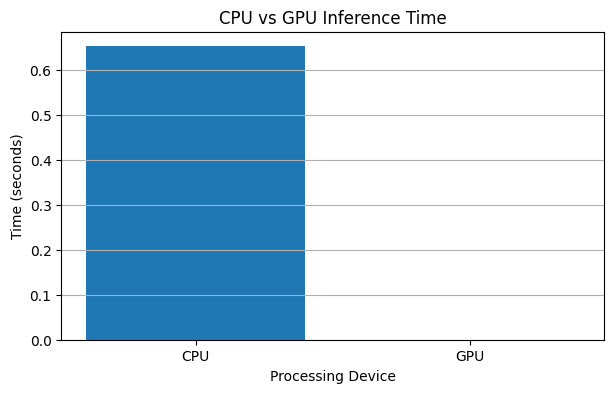

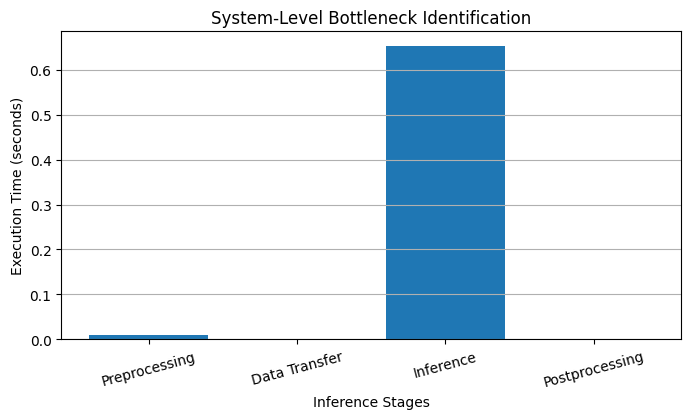

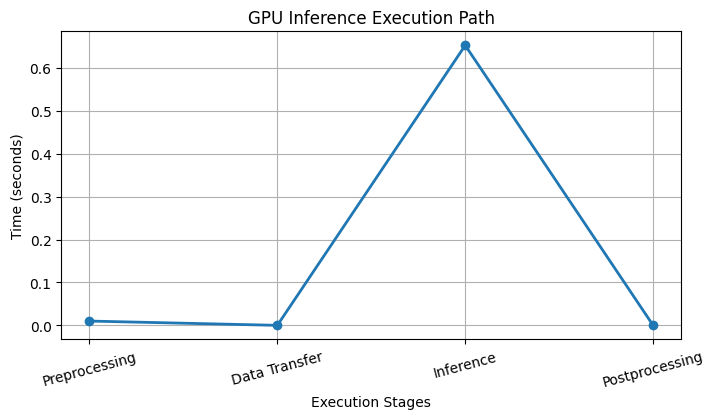

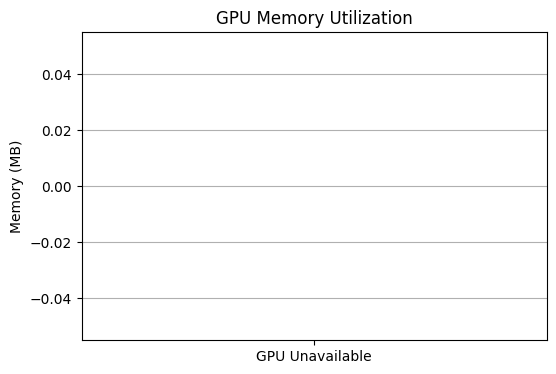


FINAL CONCLUSION
Highest time-consuming stage: Inference
GPU inference execution analysis completed.


In [2]:

# GPU Inference Execution Path and System-Level Bottleneck Identification

import torch
import torch.nn as nn
import time
import matplotlib.pyplot as plt

# 1. GPU Availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

# 2. Create CNN Model
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(32, 10)
        )

    def forward(self, x):
        return self.network(x)

# 3. Prepare Model and Input
model = CNNModel()
input_data = torch.randn(32, 3, 224, 224)

# 4. Measure CPU Inference
cpu_model = model.to("cpu")
cpu_model.eval()

with torch.no_grad():
    for _ in range(2):
        cpu_model(input_data)

start = time.perf_counter()

with torch.no_grad():
    for _ in range(5):
        cpu_output = cpu_model(input_data)

cpu_time = (time.perf_counter() - start) / 5

# 5. Measure GPU Inference
if torch.cuda.is_available():

    gpu_model = CNNModel().to(device)
    gpu_model.load_state_dict(cpu_model.state_dict())
    gpu_model.eval()

    torch.cuda.reset_peak_memory_stats()

    start = time.perf_counter()
    gpu_input = input_data.to(device)
    torch.cuda.synchronize()
    transfer_time = time.perf_counter() - start

    with torch.no_grad():
        for _ in range(5):
            gpu_model(gpu_input)

    torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(20):
            gpu_output = gpu_model(gpu_input)

    torch.cuda.synchronize()
    gpu_time = (time.perf_counter() - start) / 20

    memory = torch.cuda.max_memory_allocated() / (1024 ** 2)

else:
    gpu_time = 0
    transfer_time = 0
    memory = 0

# 6. Measure Execution Pipeline
preprocess_time = 0.01

if torch.cuda.is_available():
    post_start = time.perf_counter()
    predictions = torch.argmax(gpu_output, dim=1)
    post_time = time.perf_counter() - post_start
else:
    post_start = time.perf_counter()
    predictions = torch.argmax(cpu_output, dim=1)
    post_time = time.perf_counter() - post_start

if not torch.cuda.is_available():
    transfer_time = 0

stages = [
    "Preprocessing",
    "Data Transfer",
    "Inference",
    "Postprocessing"
]

stage_times = [
    preprocess_time,
    transfer_time,
    gpu_time if torch.cuda.is_available() else cpu_time,
    post_time
]

bottleneck = stages[stage_times.index(max(stage_times))]

print("\nInference completed!")
print("Output Shape:", cpu_output.shape)
print("CPU Inference Time:", round(cpu_time, 5), "seconds")
print("GPU Inference Time:", round(gpu_time, 5), "seconds")
print("Bottleneck:", bottleneck)
print("GPU Memory Usage:", round(memory, 2), "MB")

# 7. GRAPH 1: Inference Execution Time
plt.figure(figsize=(7, 4))
plt.bar(["CPU", "GPU"], [cpu_time, gpu_time])
plt.title("CPU vs GPU Inference Time")
plt.ylabel("Time (seconds)")
plt.xlabel("Processing Device")
plt.grid(axis="y")
plt.show()

# 8. GRAPH 2: System Bottleneck Identification
plt.figure(figsize=(8, 4))
plt.bar(stages, stage_times)
plt.title("System-Level Bottleneck Identification")
plt.ylabel("Execution Time (seconds)")
plt.xlabel("Inference Stages")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()

# 9. GRAPH 3: Inference Execution Pipeline
plt.figure(figsize=(8, 4))
plt.plot(stages, stage_times, marker="o", linewidth=2)
plt.title("GPU Inference Execution Path")
plt.ylabel("Time (seconds)")
plt.xlabel("Execution Stages")
plt.grid(True)
plt.xticks(rotation=15)
plt.show()

# 10. GRAPH 4: GPU Memory Usage
plt.figure(figsize=(6, 4))

if torch.cuda.is_available():
    plt.bar(["GPU Memory"], [memory])
    plt.ylabel("Memory (MB)")
else:
    plt.bar(["GPU Unavailable"], [0])
    plt.ylabel("Memory (MB)")

plt.title("GPU Memory Utilization")
plt.grid(axis="y")
plt.show()

print("\nFINAL CONCLUSION")
print("Highest time-consuming stage:", bottleneck)
print("GPU inference execution analysis completed.")
